# Segmentación de clientes de tarjeta de crédito con machine learning no supervisado

Trabajo final de Introducción a Machine Learning, Especialización en Inteligencia Artificial, Universidad de Cundinamarca. Kevin Esteban Chiquillo Díaz.

En este notebook busco perfiles de clientes de tarjeta de crédito con dos algoritmos de agrupamiento, K-Means y DBSCAN, usando el Credit Card Dataset for Clustering (Bhasin, 2018) que está publicado en Kaggle. Lo organicé en las siete fases del trabajo final, más una fase inicial para dejar listo el entorno.

| Fase | Contenido |
|---|---|
| 0 | Configuración del entorno, en local o en Google Colab |
| 1 | Descripción del problema |
| 2 | Fuente de datos y diccionario de variables |
| 3 | Análisis exploratorio de datos |
| 4 | Preprocesamiento |
| 5 | Implementación de los dos algoritmos |
| 6 | Evaluación del desempeño |
| 7 | Interpretación y selección del algoritmo |

Las interpretaciones las escribí después de correr todo con los datos reales. Si se cambia algún parámetro, las cifras del texto pueden dejar de coincidir.

## Fase 0. Configuración del entorno

Cargo las librerías, fijo la semilla en 42 para que los resultados se puedan repetir y dejo listo el estilo de las gráficas.

In [1]:
import os
import sys
import time
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
np.random.seed(SEMILLA)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

EN_COLAB = "google.colab" in sys.modules
print("Ejecutando en Google Colab" if EN_COLAB else "Ejecutando en local")

Ejecutando en local


### Rutas del proyecto

El notebook funciona igual en mi computador y en Google Colab. En local busca la carpeta del proyecto, la que tiene `data` y `notebooks`. En Colab clona el repositorio de GitHub que está en `REPO_URL` y usa el CSV que viene incluido. Si por alguna razón no lo encuentra, pide subir el archivo a mano.

Al final de la celda hay dos funciones pequeñas que guardan las figuras en `reports/figures` y las tablas en `reports/tablas`, para usarlas después en el informe.

In [2]:
REPO_URL = "https://github.com/Kevinn-19/proyecto-final-ml.git"

NOMBRE_ARCHIVO = "CC GENERAL.csv"


def encontrar_raiz():
    if EN_COLAB and REPO_URL:
        nombre_repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
        destino = Path("/content") / nombre_repo
        if not destino.exists():
            subprocess.run(["git", "clone", REPO_URL, str(destino)], check=True)
        return destino
    actual = Path.cwd()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "data").is_dir() and (carpeta / "notebooks").is_dir():
            return carpeta
    return actual


RAIZ = encontrar_raiz()
DIR_RAW = RAIZ / "data" / "raw"
DIR_PROCESADOS = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "reports" / "figures"
DIR_TABLAS = RAIZ / "reports" / "tablas"
for carpeta in [DIR_RAW, DIR_PROCESADOS, DIR_FIGURAS, DIR_TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

RUTA_DATOS = Path(os.environ.get("CC_DATA_PATH", DIR_RAW / NOMBRE_ARCHIVO))

if not RUTA_DATOS.exists():
    if EN_COLAB:
        from google.colab import files
        print(f"No se encontró '{NOMBRE_ARCHIVO}'. Súbelo desde tu computador:")
        subidos = files.upload()
        nombre_subido = next(iter(subidos))
        RUTA_DATOS = DIR_RAW / NOMBRE_ARCHIVO
        RUTA_DATOS.write_bytes(subidos[nombre_subido])
    else:
        raise FileNotFoundError(
            f"No se encontró el dataset en {RUTA_DATOS}.\n"
            "Descárgalo de https://www.kaggle.com/datasets/arjunbhasin2013/ccdata "
            "y guarda 'CC GENERAL.csv' en la carpeta data/raw/."
        )

print("Raíz del proyecto:", RAIZ)
print("Dataset:", RUTA_DATOS)


def guardar_figura(nombre):
    plt.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight")


def guardar_tabla(tabla, nombre):
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", encoding="utf-8-sig")

Raíz del proyecto: C:\Users\kevin\OneDrive\Documentos\Proyecto Final ML
Dataset: C:\Users\kevin\OneDrive\Documentos\Proyecto Final ML\data\raw\CC GENERAL.csv


## Fase 1. Descripción del problema

- Problema: una entidad financiera tiene miles de clientes con tarjeta de crédito y no sabe bien qué tipos de cliente tiene. Sin esa información termina diseñando las campañas, los cupos y las alertas de riesgo igual para todos.
- Información disponible: el comportamiento de unos 9.000 titulares activos durante seis meses, con su saldo, sus compras, sus avances en efectivo, sus pagos y su cupo.
- Por qué es no supervisado: ninguna variable dice a qué segmento pertenece cada cliente. Los grupos no se predicen, hay que descubrirlos en los datos.
- Patrones que esperaba: clientes que pagan el total cada mes, clientes que mantienen saldo y pagan el mínimo, clientes que usan mucho los avances en efectivo, compradores a cuotas y clientes casi inactivos.
- Utilidad: si esos grupos aparecen, sirven para hacer campañas por segmento, ajustar cupos, anticiparse al riesgo de impago y detectar comportamientos raros.

La pregunta que quiero responder es esta.

> ¿Qué perfiles de comportamiento en el uso de tarjetas de crédito existen entre los titulares del dataset, y cuál de los algoritmos K-Means y DBSCAN los identifica con mayor calidad de agrupamiento?

## Fase 2. Fuente de datos

Uso el archivo CC GENERAL.csv del Credit Card Dataset for Clustering, que Arjun Bhasin publicó en Kaggle en 2018 con licencia de dominio público. Cada fila es un titular de tarjeta y las columnas resumen cómo usó la tarjeta en los últimos seis meses. No trae etiquetas. Se puede descargar desde [Kaggle](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata).

Hay que tener en cuenta que el autor no dice de qué entidad salieron los datos ni en qué moneda están los montos, y que los clientes vienen anonimizados.

In [3]:
df = pd.read_csv(RUTA_DATOS)

print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")
df.head()

Registros: 8,950
Variables: 18


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.901,0.818,95.400,0.000,95.400,0.000,0.167,0.000,0.083,0.000,0,2,"1,000.000",201.802,139.510,0.000,12
1,C10002,"3,202.467",0.909,0.000,0.000,0.000,"6,442.945",0.000,0.000,0.000,0.250,4,0,"7,000.000","4,103.033","1,072.340",0.222,12
2,C10003,"2,495.149",1.000,773.170,773.170,0.000,0.000,1.000,1.000,0.000,0.000,0,12,"7,500.000",622.067,627.285,0.000,12
3,C10004,"1,666.671",0.636,"1,499.000","1,499.000",0.000,205.788,0.083,0.083,0.000,0.083,1,1,"7,500.000",0.000,NaN,0.000,12
4,C10005,817.714,1.000,16.000,16.000,0.000,0.000,0.083,0.083,0.000,0.000,0,1,"1,200.000",678.335,244.791,0.000,12


### Diccionario de variables

Esta tabla explica qué significa cada columna. También la guardo en `reports/tablas` para el informe.

In [4]:
DICCIONARIO = {
    "CUST_ID": "Identificador del titular (no se usa en el modelo)",
    "BALANCE": "Saldo pendiente en la cuenta",
    "BALANCE_FREQUENCY": "Frecuencia con que se actualiza el saldo (0 a 1)",
    "PURCHASES": "Monto total de compras",
    "ONEOFF_PURCHASES": "Monto de compras hechas en un solo pago",
    "INSTALLMENTS_PURCHASES": "Monto de compras hechas a cuotas",
    "CASH_ADVANCE": "Monto de avances en efectivo",
    "PURCHASES_FREQUENCY": "Frecuencia de compras (0 a 1)",
    "ONEOFF_PURCHASES_FREQUENCY": "Frecuencia de compras en un solo pago (0 a 1)",
    "PURCHASES_INSTALLMENTS_FREQUENCY": "Frecuencia de compras a cuotas (0 a 1)",
    "CASH_ADVANCE_FREQUENCY": "Frecuencia de avances en efectivo (0 a 1)",
    "CASH_ADVANCE_TRX": "Número de transacciones de avance en efectivo",
    "PURCHASES_TRX": "Número de transacciones de compra",
    "CREDIT_LIMIT": "Cupo de la tarjeta",
    "PAYMENTS": "Monto total pagado",
    "MINIMUM_PAYMENTS": "Monto de pagos mínimos realizados",
    "PRC_FULL_PAYMENT": "Porcentaje de meses en que se pagó el total (0 a 1)",
    "TENURE": "Antigüedad del servicio de tarjeta (meses)",
}

tabla_diccionario = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Descripción": [DICCIONARIO.get(c, "") for c in df.columns],
})
guardar_tabla(tabla_diccionario.set_index("Variable"), "diccionario_variables")
tabla_diccionario

,Variable,Tipo,Descripción
0,CUST_ID,str,Identificador del titular (no se usa en el mod...
1,BALANCE,float64,Saldo pendiente en la cuenta
2,BALANCE_FREQUENCY,float64,Frecuencia con que se actualiza el saldo (0 a 1)
3,PURCHASES,float64,Monto total de compras
4,ONEOFF_PURCHASES,float64,Monto de compras hechas en un solo pago
5,INSTALLMENTS_PURCHASES,float64,Monto de compras hechas a cuotas
6,CASH_ADVANCE,float64,Monto de avances en efectivo
7,PURCHASES_FREQUENCY,float64,Frecuencia de compras (0 a 1)
8,ONEOFF_PURCHASES_FREQUENCY,float64,Frecuencia de compras en un solo pago (0 a 1)
9,PURCHASES_INSTALLMENTS_FREQUENCY,float64,Frecuencia de compras a cuotas (0 a 1)


## Fase 3. Análisis exploratorio de datos

### 3.1 Registros, variables y estadísticas descriptivas

Empiezo por lo básico, cuántos registros hay y cómo se comporta cada variable. Agregué la asimetría porque los montos de una tarjeta suelen estar muy cargados hacia un lado.

In [5]:
COLUMNA_ID = "CUST_ID"
numericas = df.select_dtypes(include="number").columns.tolist()

print(f"Registros: {len(df):,} | Variables numéricas: {len(numericas)}")

descriptivas = df[numericas].describe().T
descriptivas["asimetría"] = df[numericas].skew()
guardar_tabla(descriptivas, "estadisticas_descriptivas")
descriptivas

Registros: 8,950 | Variables numéricas: 17


,count,mean,std,min,25%,50%,75%,max,asimetría
BALANCE,"8,950.000","1,564.475","2,081.532",0.000,128.282,873.385,"2,054.140","19,043.139",2.393
BALANCE_FREQUENCY,"8,950.000",0.877,0.237,0.000,0.889,1.000,1.000,1.000,-2.023
PURCHASES,"8,950.000","1,003.205","2,136.635",0.000,39.635,361.280,"1,110.130","49,039.570",8.144
ONEOFF_PURCHASES,"8,950.000",592.437,"1,659.888",0.000,0.000,38.000,577.405,"40,761.250",10.045
INSTALLMENTS_PURCHASES,"8,950.000",411.068,904.338,0.000,0.000,89.000,468.637,"22,500.000",7.299
CASH_ADVANCE,"8,950.000",978.871,"2,097.164",0.000,0.000,0.000,"1,113.821","47,137.212",5.167
PURCHASES_FREQUENCY,"8,950.000",0.490,0.401,0.000,0.083,0.500,0.917,1.000,0.060
ONEOFF_PURCHASES_FREQUENCY,"8,950.000",0.202,0.298,0.000,0.000,0.083,0.300,1.000,1.536
PURCHASES_INSTALLMENTS_FREQUENCY,"8,950.000",0.364,0.397,0.000,0.000,0.167,0.750,1.000,0.509
CASH_ADVANCE_FREQUENCY,"8,950.000",0.135,0.200,0.000,0.000,0.000,0.222,1.500,1.829


### 3.2 Valores faltantes y registros duplicados

Además de contar los faltantes quise ver si tenían alguna explicación, porque de eso depende cómo rellenarlos. Por eso reviso cuántos de los clientes sin MINIMUM_PAYMENTS tienen los pagos en cero.

In [6]:
faltantes = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)
guardar_tabla(faltantes, "valores_faltantes")

dup_filas = df.duplicated().sum()
dup_id = df[COLUMNA_ID].duplicated().sum() if COLUMNA_ID in df else 0
dup_sin_id = df.drop(columns=[COLUMNA_ID], errors="ignore").duplicated().sum()

print(f"Filas duplicadas completas: {dup_filas}")
print(f"IDs de cliente repetidos: {dup_id}")
print(f"Filas iguales ignorando el ID: {dup_sin_id}")
print()

falta_min = df["MINIMUM_PAYMENTS"].isna()
print(f"Clientes sin MINIMUM_PAYMENTS: {falta_min.sum()}")
print(f"  de ellos con PAYMENTS = 0: {(falta_min & (df['PAYMENTS'] == 0)).sum()}")
print(f"Clientes con PAYMENTS = 0 en todo el dataset: {(df['PAYMENTS'] == 0).sum()}")
print()
print("Variables con valores faltantes:")
faltantes

Filas duplicadas completas: 0
IDs de cliente repetidos: 0
Filas iguales ignorando el ID: 0

Clientes sin MINIMUM_PAYMENTS: 313
  de ellos con PAYMENTS = 0: 240
Clientes con PAYMENTS = 0 en todo el dataset: 240

Variables con valores faltantes:


,faltantes,porcentaje
MINIMUM_PAYMENTS,313,3.500
CREDIT_LIMIT,1,0.010


### 3.3 Valores atípicos

Para contar los atípicos uso la regla del rango intercuartílico. Un valor es atípico si queda por debajo del primer cuartil menos 1,5 veces el IQR, o por encima del tercer cuartil más 1,5 veces el IQR. Después de la tabla dibujo los diagramas de caja de todas las variables.

In [7]:
def contar_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()


atipicos = pd.DataFrame({
    "atípicos": df[numericas].apply(contar_atipicos),
})
atipicos["porcentaje"] = (atipicos["atípicos"] / len(df) * 100).round(2)
atipicos = atipicos.sort_values("atípicos", ascending=False)
guardar_tabla(atipicos, "valores_atipicos")
atipicos

,atípicos,porcentaje
BALANCE_FREQUENCY,1493,16.680
PRC_FULL_PAYMENT,1474,16.470
TENURE,1366,15.260
CASH_ADVANCE,1030,11.510
ONEOFF_PURCHASES,1013,11.320
INSTALLMENTS_PURCHASES,867,9.690
MINIMUM_PAYMENTS,841,9.400
PAYMENTS,808,9.030
PURCHASES,808,9.030
CASH_ADVANCE_TRX,804,8.980


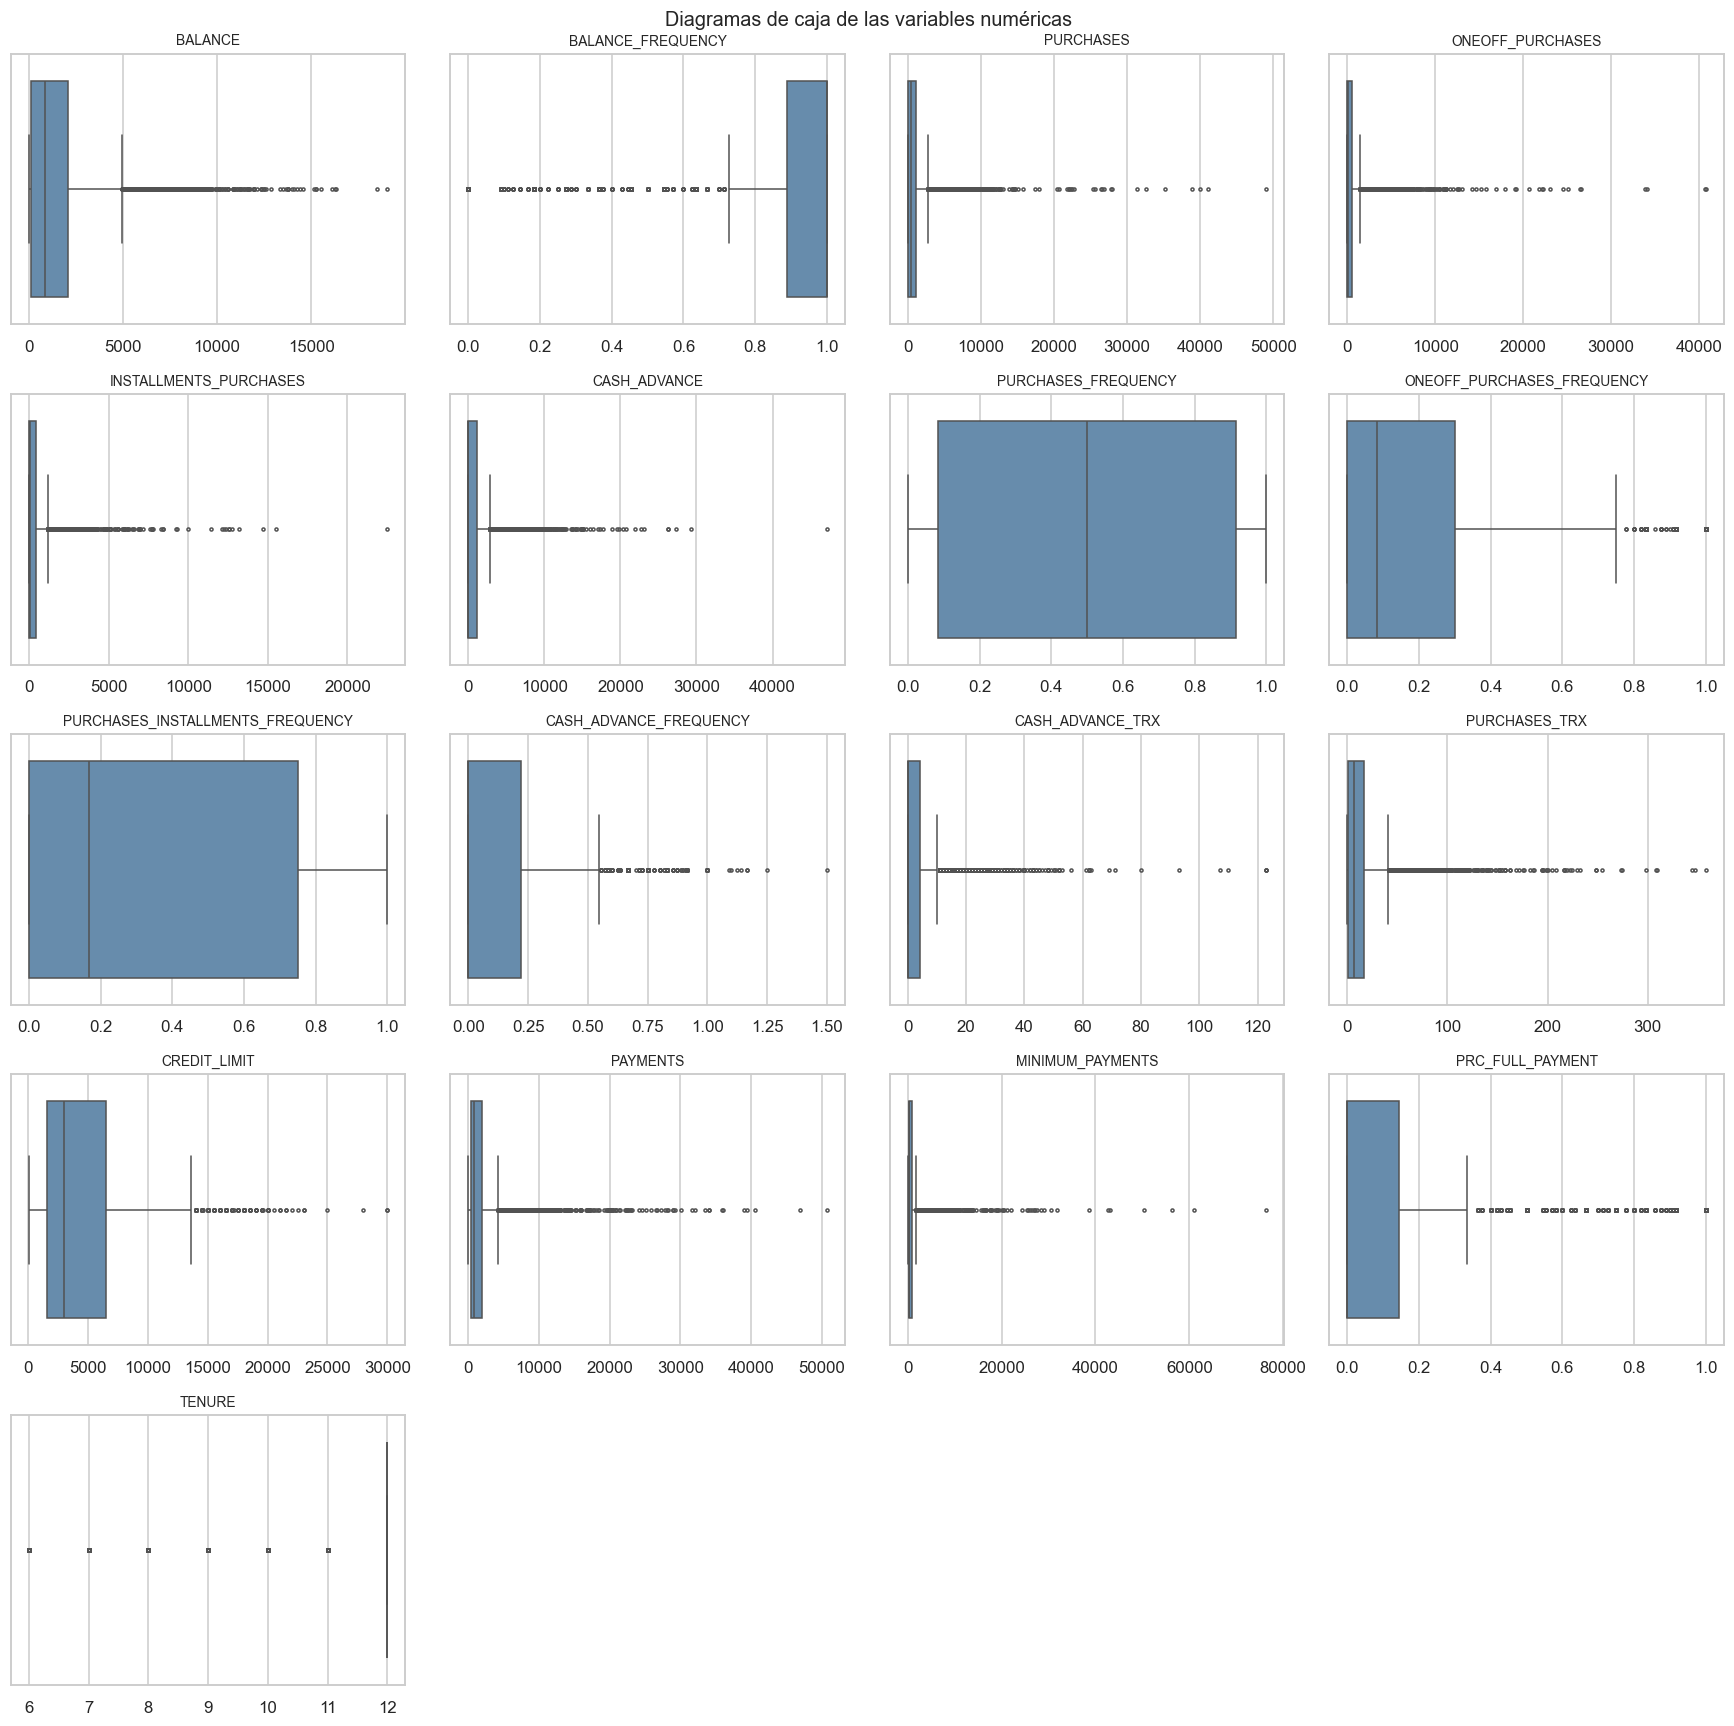

In [8]:
n_cols = 4
n_filas = int(np.ceil(len(numericas) / n_cols))
fig, ejes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas))
for eje, col in zip(ejes.flat, numericas):
    sns.boxplot(x=df[col], ax=eje, color="#5B8DB8", fliersize=2)
    eje.set_title(col, fontsize=9)
    eje.set_xlabel("")
for eje in list(ejes.flat)[len(numericas):]:
    eje.set_visible(False)
fig.suptitle("Diagramas de caja de las variables numéricas", fontsize=13)
plt.tight_layout()
guardar_figura("eda_01_diagramas_caja")
plt.show()

### 3.4 Distribución de las variables

En el título de cada histograma puse la asimetría, para ver de una vez cuáles variables están más sesgadas.

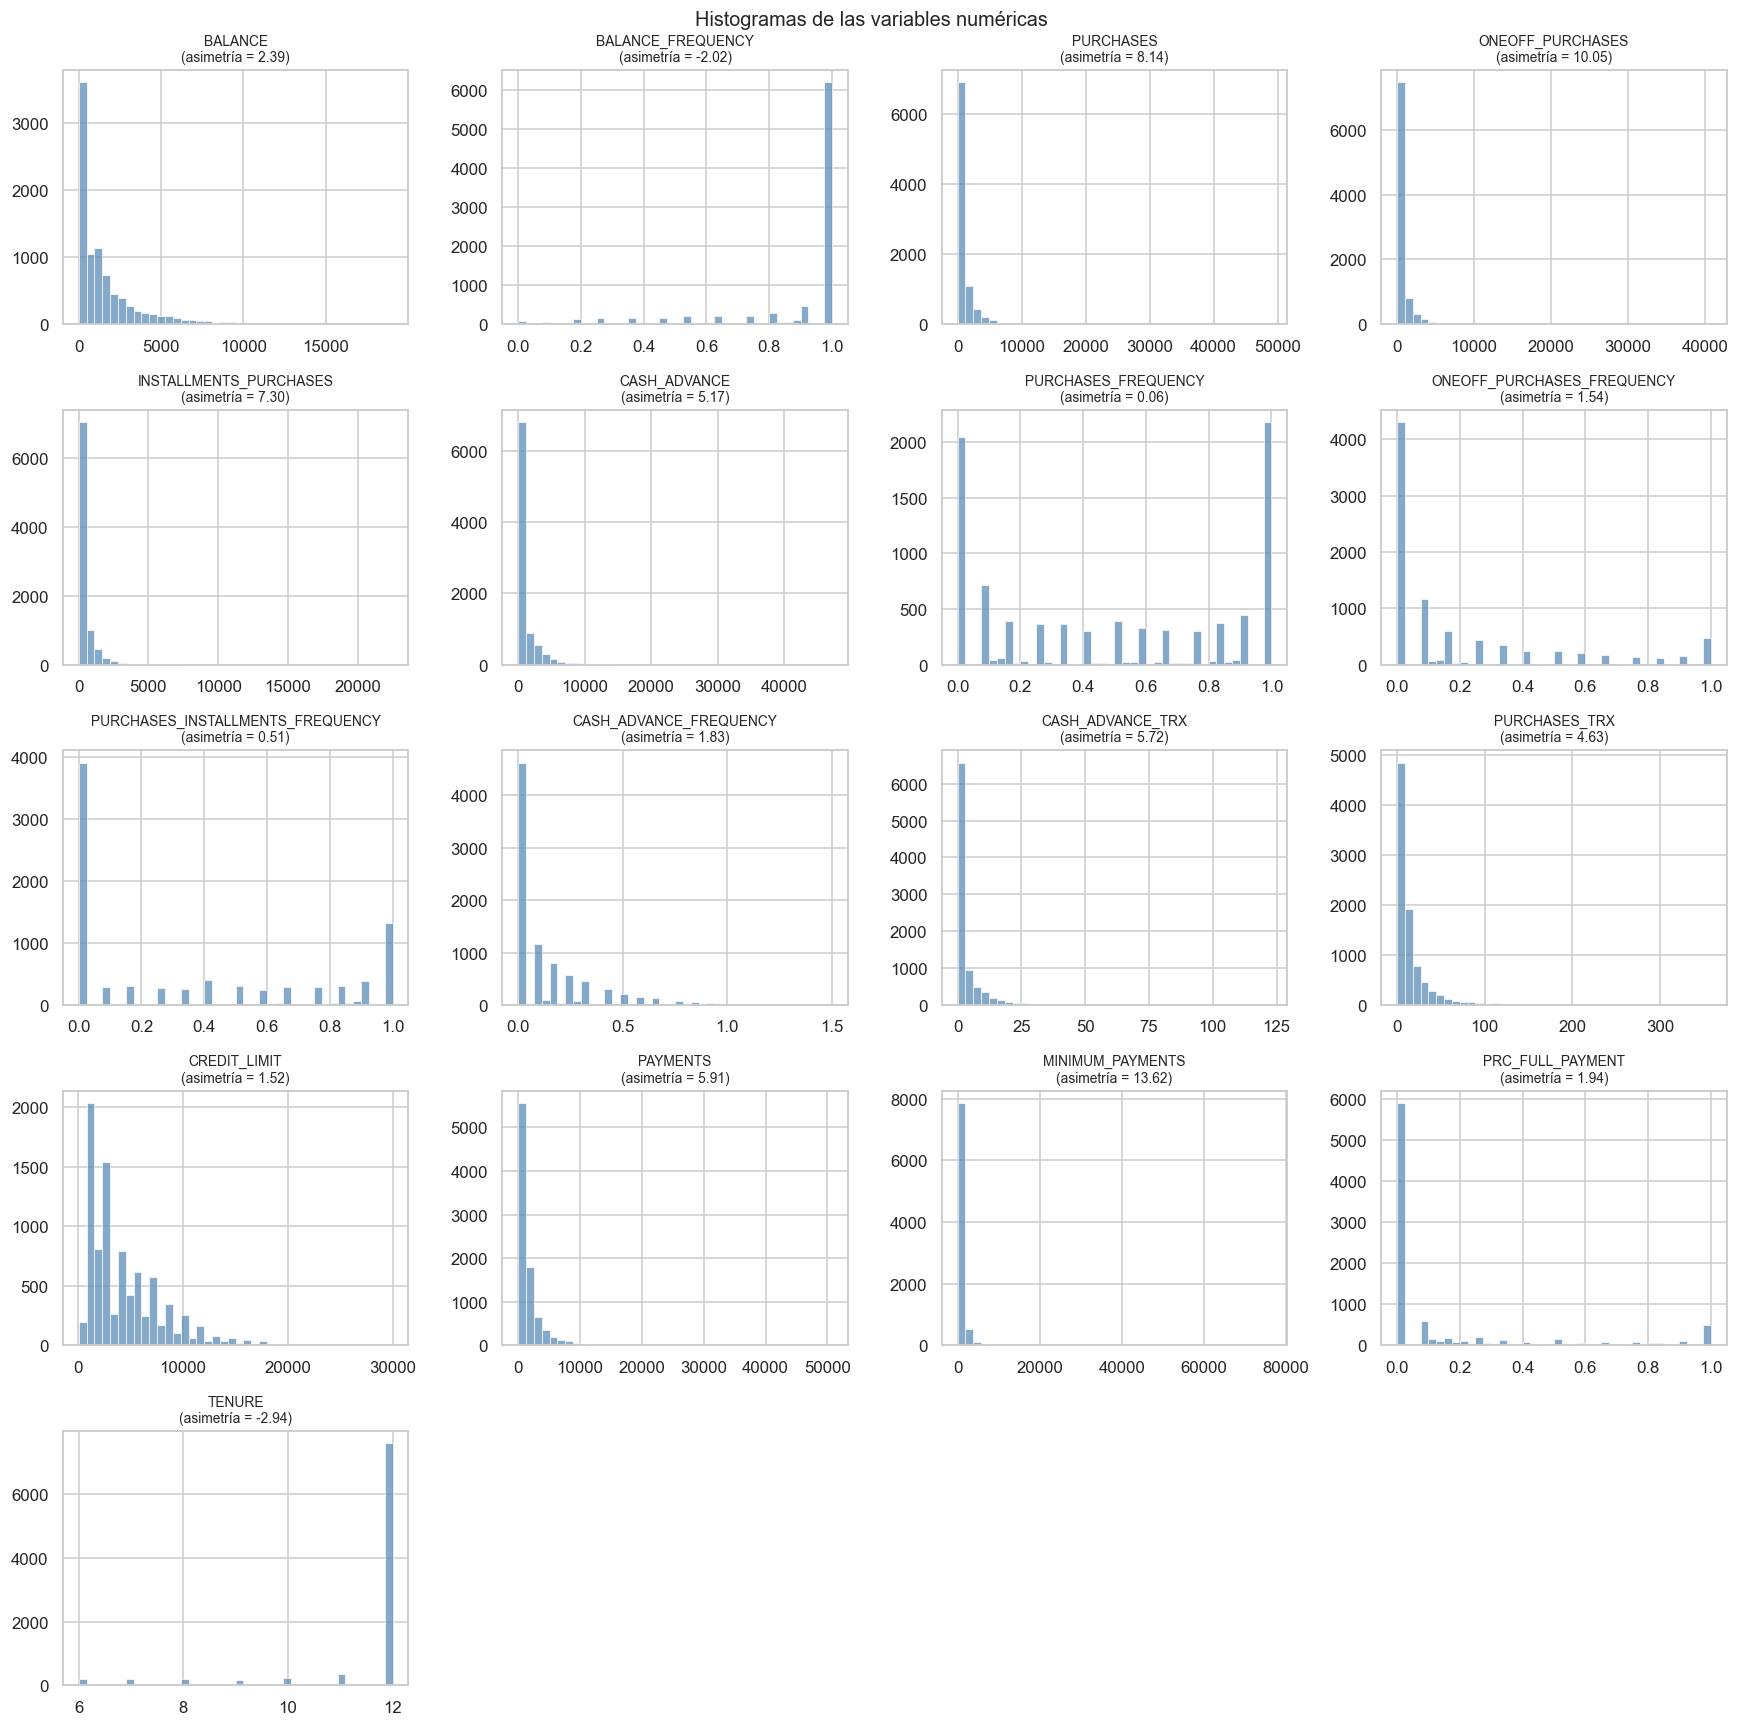

In [9]:
fig, ejes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas))
for eje, col in zip(ejes.flat, numericas):
    sns.histplot(df[col].dropna(), bins=40, ax=eje, color="#5B8DB8")
    eje.set_title(f"{col}\n(asimetría = {df[col].skew():.2f})", fontsize=9)
    eje.set_xlabel("")
    eje.set_ylabel("")
for eje in list(ejes.flat)[len(numericas):]:
    eje.set_visible(False)
fig.suptitle("Histogramas de las variables numéricas", fontsize=13)
plt.tight_layout()
guardar_figura("eda_02_histogramas")
plt.show()

### 3.5 Relaciones entre variables

La matriz de correlación me sirve para ver qué variables dicen casi lo mismo. Debajo de la gráfica imprimo los pares con correlación de 0,7 o más en valor absoluto.

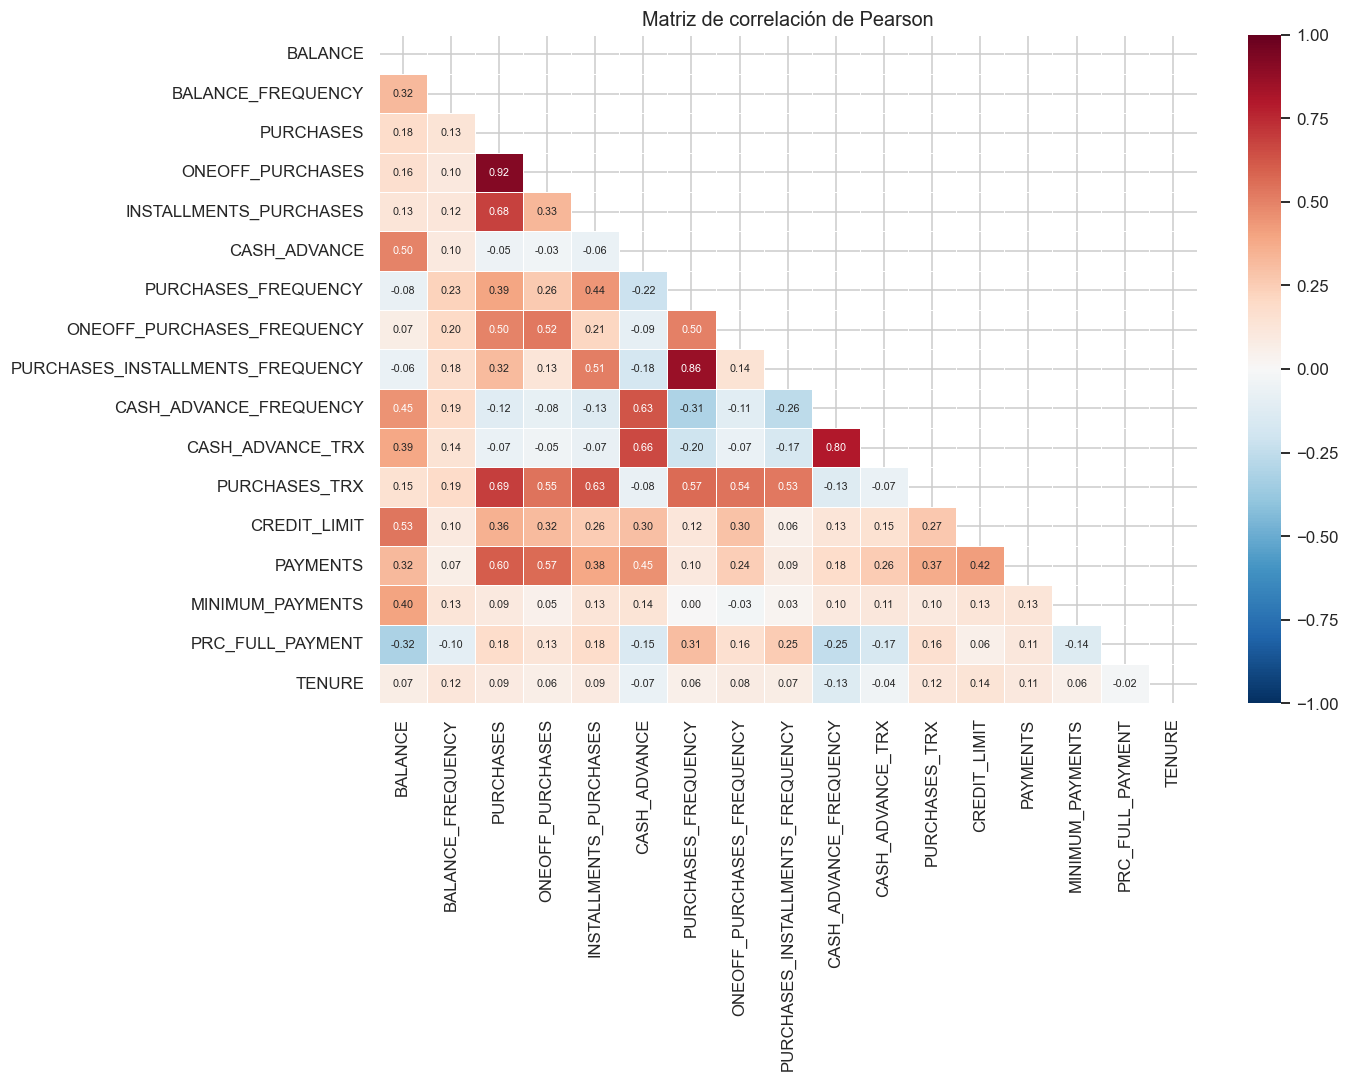

Pares con |r| >= 0.7:


,variable_1,variable_2,r
37,PURCHASES,ONEOFF_PURCHASES,0.917
110,PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,0.863
163,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,0.800


In [10]:
correlacion = df[numericas].corr()

plt.figure(figsize=(13, 10))
mascara = np.triu(np.ones_like(correlacion, dtype=bool))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, linewidths=0.5)
plt.title("Matriz de correlación de Pearson", fontsize=13)
plt.tight_layout()
guardar_figura("eda_03_matriz_correlacion")
plt.show()

pares = (
    correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1))
    .stack()
    .rename("r")
    .reset_index()
    .rename(columns={"level_0": "variable_1", "level_1": "variable_2"})
)
pares_altos = pares[pares["r"].abs() >= 0.7].sort_values("r", key=abs, ascending=False)
guardar_tabla(pares_altos.set_index(["variable_1", "variable_2"]), "correlaciones_altas")
print("Pares con |r| >= 0.7:")
pares_altos

### 3.6 Diagramas de dispersión

Escogí cuatro pares de variables que me parecieron interesantes. Como los montos están tan sesgados los muestro en escala logarítmica, si no casi todos los puntos quedan amontonados en una esquina.

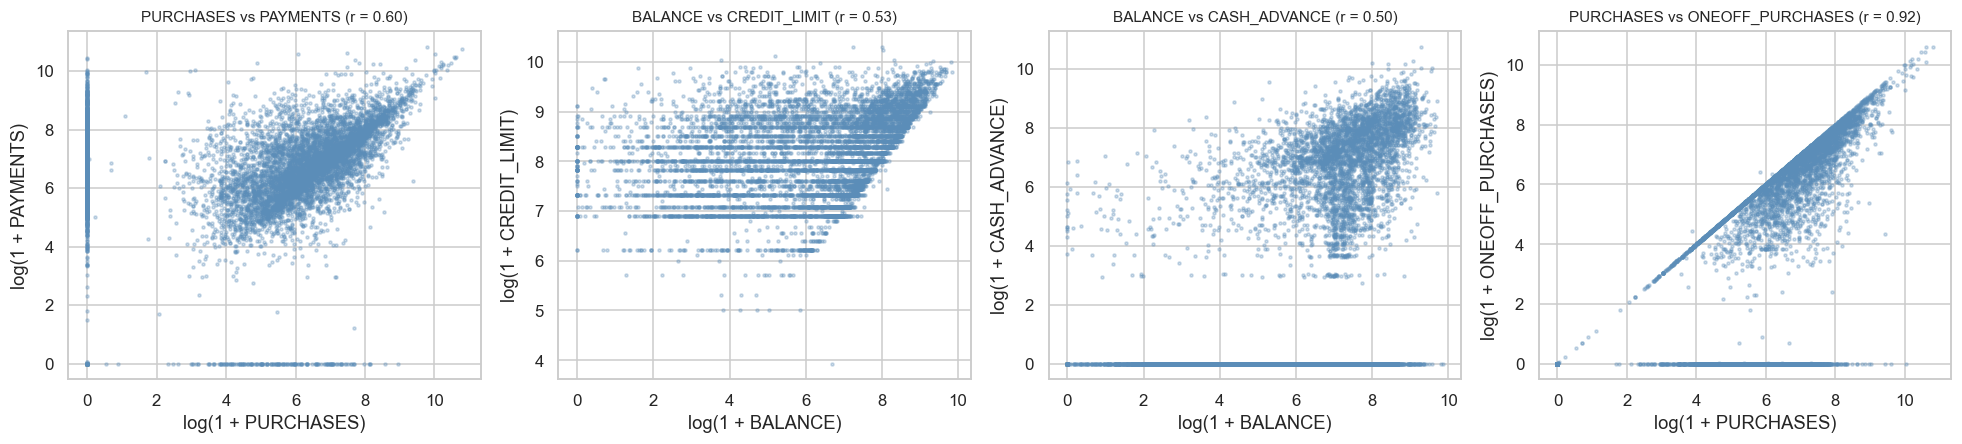

In [11]:
PARES_DISPERSION = [
    ("PURCHASES", "PAYMENTS"),
    ("BALANCE", "CREDIT_LIMIT"),
    ("BALANCE", "CASH_ADVANCE"),
    ("PURCHASES", "ONEOFF_PURCHASES"),
]

fig, ejes = plt.subplots(1, len(PARES_DISPERSION), figsize=(18, 4.2))
for eje, (x, y) in zip(ejes, PARES_DISPERSION):
    eje.scatter(np.log1p(df[x]), np.log1p(df[y]), s=4, alpha=0.3, color="#5B8DB8")
    r = df[[x, y]].corr().iloc[0, 1]
    eje.set_xlabel(f"log(1 + {x})")
    eje.set_ylabel(f"log(1 + {y})")
    eje.set_title(f"{x} vs {y} (r = {r:.2f})", fontsize=10)
plt.tight_layout()
guardar_figura("eda_04_dispersion")
plt.show()

### Lo que encontré en el análisis exploratorio

- Tamaño: 8.950 registros y 18 variables, 17 numéricas y el identificador `CUST_ID`. Cumple de sobra con los requisitos del trabajo, que piden al menos 1.000 registros y 4 variables.
- Valores faltantes: solo hay en dos columnas, `MINIMUM_PAYMENTS` con 313 (3,5 %) y `CREDIT_LIMIT` con 1. Aquí apareció algo que terminó siendo clave. Los 240 clientes con `PAYMENTS` en cero están todos entre los que no tienen `MINIMUM_PAYMENTS`, o sea que el dato no falta por azar, falta porque el cliente no hizo ningún pago. Eso lo tengo en cuenta en el preprocesamiento.
- Duplicados: no hay filas ni identificadores repetidos.
- Atípicos: la regla del IQR marca entre el 8 % y el 12 % de los montos de compras, avances y pagos. No los considero errores, son clientes reales que usan la tarjeta mucho más que los demás, así que no los borro y prefiero bajarles el peso con un logaritmo. En `BALANCE_FREQUENCY`, `PRC_FULL_PAYMENT` y `TENURE` salen tantos atípicos porque casi todos los clientes tienen el mismo valor, por ejemplo 12 meses de antigüedad.
- Distribuciones: los montos están muy sesgados a la derecha, con asimetría de 13,6 en `MINIMUM_PAYMENTS`, 10,0 en `ONEOFF_PURCHASES` y 8,1 en `PURCHASES`. Si no los transformo, unos pocos clientes van a dominar las distancias de K-Means y DBSCAN.
- Correlaciones: varias variables repiten información. `PURCHASES` y `ONEOFF_PURCHASES` tienen r = 0,92, y `PURCHASES_FREQUENCY` y `PURCHASES_INSTALLMENTS_FREQUENCY` tienen r = 0,86. Las frecuencias y los conteos de transacciones también miden casi lo mismo, por eso más adelante hago una selección de variables.

## Fase 4. Preprocesamiento

En esta celda limpio los datos. La tabla que sale al final resume cada paso y cuántos registros quedan después de él.

- Identificador: quito `CUST_ID` porque solo sirve para identificar al cliente.
- Faltantes en `CREDIT_LIMIT`: es una sola fila, así que la elimino.
- Faltantes en `MINIMUM_PAYMENTS`: a los clientes que no hicieron ningún pago les pongo cero, porque su pago mínimo de verdad fue cero, y al resto les pongo la mediana. En una primera versión rellené todo con la mediana y DBSCAN me armó un grupo falso, formado por clientes sin pagos a los que yo mismo les había inventado un pago mínimo normal. Por eso cambié a estas dos reglas.
- Duplicados: los reviso, aunque no hay ninguno.
- Variables de texto: no hay, así que no tengo que codificar nada.

In [12]:
datos = df.copy()
registro = []

datos = datos.drop(columns=[COLUMNA_ID], errors="ignore")
registro.append(("Eliminar identificador", f"Se elimina {COLUMNA_ID}", len(datos)))

n_antes = len(datos)
datos = datos.dropna(subset=["CREDIT_LIMIT"])
registro.append(("Faltantes en CREDIT_LIMIT", f"Se eliminan {n_antes - len(datos)} filas", len(datos)))

faltante_min = datos["MINIMUM_PAYMENTS"].isna()
sin_pagos = faltante_min & (datos["PAYMENTS"] == 0)
datos.loc[sin_pagos, "MINIMUM_PAYMENTS"] = 0
registro.append(("Faltantes en MINIMUM_PAYMENTS (sin pagos)",
                 f"{sin_pagos.sum()} clientes con PAYMENTS = 0: se imputa 0", len(datos)))

resto = datos["MINIMUM_PAYMENTS"].isna()
mediana_pagos_min = datos.loc[~faltante_min, "MINIMUM_PAYMENTS"].median()
datos.loc[resto, "MINIMUM_PAYMENTS"] = mediana_pagos_min
registro.append(("Faltantes en MINIMUM_PAYMENTS (resto)",
                 f"Se imputan {resto.sum()} valores con la mediana ({mediana_pagos_min:,.2f})", len(datos)))

otros = datos.columns[datos.isna().any()].tolist()
for col in otros:
    datos[col] = datos[col].fillna(datos[col].median())
if otros:
    registro.append(("Otros faltantes", f"Imputados con la mediana: {otros}", len(datos)))

n_antes = len(datos)
datos = datos.drop_duplicates()
registro.append(("Duplicados", f"Se eliminan {n_antes - len(datos)} filas", len(datos)))

categoricas = datos.select_dtypes(exclude="number").columns.tolist()
registro.append(("Variables categóricas",
                 "No hay; no se requiere codificación" if not categoricas else f"Codificar: {categoricas}",
                 len(datos)))

datos = datos.reset_index(drop=True)
tabla_registro = pd.DataFrame(registro, columns=["Paso", "Acción", "Registros resultantes"])
guardar_tabla(tabla_registro.set_index("Paso"), "preprocesamiento_bitacora")
tabla_registro

,Paso,Acción,Registros resultantes
0,Eliminar identificador,Se elimina CUST_ID,8950
1,Faltantes en CREDIT_LIMIT,Se eliminan 1 filas,8949
2,Faltantes en MINIMUM_PAYMENTS (sin pagos),240 clientes con PAYMENTS = 0: se imputa 0,8949
3,Faltantes en MINIMUM_PAYMENTS (resto),Se imputan 73 valores con la mediana (312.45),8949
4,Duplicados,Se eliminan 0 filas,8949
5,Variables categóricas,No hay; no se requiere codificación,8949


### 4.5 Transformación logarítmica

Los montos y los conteos tienen una asimetría muy alta, con unos pocos clientes que manejan valores enormes. Les aplico `log(1 + x)` para que esos clientes no dominen las distancias. Las frecuencias no las toco porque ya van de 0 a 1. La tabla compara la asimetría antes y después.

In [13]:
VARIABLES_LOG = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE", "CASH_ADVANCE_TRX", "PURCHASES_TRX", "CREDIT_LIMIT",
    "PAYMENTS", "MINIMUM_PAYMENTS",
]
VARIABLES_LOG = [c for c in VARIABLES_LOG if c in datos.columns]

datos_log = datos.copy()
datos_log[VARIABLES_LOG] = np.log1p(datos_log[VARIABLES_LOG])

comparacion_asimetria = pd.DataFrame({
    "asimetría antes": datos[VARIABLES_LOG].skew(),
    "asimetría después": datos_log[VARIABLES_LOG].skew(),
})
guardar_tabla(comparacion_asimetria, "asimetria_antes_despues_log")
comparacion_asimetria

,asimetría antes,asimetría después
BALANCE,2.393,-0.861
PURCHASES,8.144,-0.765
ONEOFF_PURCHASES,10.045,0.186
INSTALLMENTS_PURCHASES,7.299,-0.025
CASH_ADVANCE,5.166,0.263
CASH_ADVANCE_TRX,5.721,0.940
PURCHASES_TRX,4.630,0.033
CREDIT_LIMIT,1.522,-0.101
PAYMENTS,5.907,-1.779
MINIMUM_PAYMENTS,13.818,-1.178


### 4.6 Selección de variables

Uso dos criterios.

- Variables casi constantes: si más del 80 % de los clientes tiene el mismo valor, quito la variable, porque casi no ayuda a separar grupos.
- Variables redundantes: si dos variables tienen una correlación de 0,80 o más en valor absoluto, me quedo solo con una. Para decidir cuál, las reviso en un orden de prioridad que puse a mano, empezando por las más generales, y descarto la que repite información de una que ya había elegido.

Los dos algoritmos trabajan exactamente con las mismas variables.

In [14]:
UMBRAL_CONSTANTE = 0.80
UMBRAL_CORRELACION = 0.80

PRIORIDAD = [
    "BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS",
    "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT", "PURCHASES_FREQUENCY",
    "CASH_ADVANCE_FREQUENCY", "BALANCE_FREQUENCY", "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES", "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY", "CASH_ADVANCE_TRX", "PURCHASES_TRX", "TENURE",
]
PRIORIDAD = [c for c in PRIORIDAD if c in datos_log.columns]
PRIORIDAD += [c for c in datos_log.columns if c not in PRIORIDAD]

decisiones = []
seleccionadas = []
corr_log = datos_log.corr()

for col in PRIORIDAD:
    proporcion_moda = datos_log[col].value_counts(normalize=True).iloc[0]
    if proporcion_moda > UMBRAL_CONSTANTE:
        decisiones.append((col, "Descartada", f"Casi constante: {proporcion_moda:.0%} de los clientes tiene el mismo valor"))
        continue
    redundante_con = [s for s in seleccionadas if abs(corr_log.loc[col, s]) >= UMBRAL_CORRELACION]
    if redundante_con:
        s = redundante_con[0]
        decisiones.append((col, "Descartada", f"Redundante con {s} (r = {corr_log.loc[col, s]:.2f})"))
        continue
    seleccionadas.append(col)
    decisiones.append((col, "Seleccionada", ""))

tabla_seleccion = pd.DataFrame(decisiones, columns=["Variable", "Decisión", "Motivo"])
guardar_tabla(tabla_seleccion.set_index("Variable"), "seleccion_variables")
print(f"Variables seleccionadas ({len(seleccionadas)}): {seleccionadas}")
tabla_seleccion

Variables seleccionadas (13): ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'BALANCE_FREQUENCY', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'ONEOFF_PURCHASES_FREQUENCY']


,Variable,Decisión,Motivo
0,BALANCE,Seleccionada,
1,PURCHASES,Seleccionada,
2,CASH_ADVANCE,Seleccionada,
3,CREDIT_LIMIT,Seleccionada,
4,PAYMENTS,Seleccionada,
5,MINIMUM_PAYMENTS,Seleccionada,
6,PRC_FULL_PAYMENT,Seleccionada,
7,PURCHASES_FREQUENCY,Seleccionada,
8,CASH_ADVANCE_FREQUENCY,Seleccionada,
9,BALANCE_FREQUENCY,Seleccionada,


### 4.7 Estandarización

K-Means y DBSCAN funcionan con distancias, así que todas las variables tienen que estar en la misma escala. Las llevo a media 0 y desviación estándar 1 y guardo el dataset preparado en `data/processed`.

In [15]:
escalador = StandardScaler()
X = pd.DataFrame(
    escalador.fit_transform(datos_log[seleccionadas]),
    columns=seleccionadas,
)

datos.to_csv(DIR_PROCESADOS / "cc_limpio.csv", index=False)
X.to_csv(DIR_PROCESADOS / "cc_preparado_estandarizado.csv", index=False)

print(f"Dataset preparado: {X.shape[0]:,} registros x {X.shape[1]} variables")
print("Guardado en data/processed/cc_preparado_estandarizado.csv")
X.describe().T[["mean", "std", "min", "max"]]

Dataset preparado: 8,949 registros x 13 variables
Guardado en data/processed/cc_preparado_estandarizado.csv


,mean,std,min,max
BALANCE,0.000,1.000,-3.061,1.834
PURCHASES,0.000,1.000,-1.680,2.023
CASH_ADVANCE,0.000,1.000,-0.931,2.087
CREDIT_LIMIT,0.000,1.000,-5.079,2.701
PAYMENTS,-0.000,1.000,-4.164,2.645
MINIMUM_PAYMENTS,0.000,1.000,-3.815,3.629
PRC_FULL_PAYMENT,0.000,1.000,-0.526,2.893
PURCHASES_FREQUENCY,-0.000,1.000,-1.222,1.270
CASH_ADVANCE_FREQUENCY,-0.000,1.000,-0.675,6.820
BALANCE_FREQUENCY,0.000,1.000,-3.705,0.518


### 4.8 PCA para visualizar

Reduzco los datos a dos dimensiones con PCA, pero solo para poder dibujar los grupos en un plano. Los algoritmos siempre trabajan con todas las variables seleccionadas.

In [16]:
pca = PCA(n_components=2, random_state=SEMILLA)
X_2d = pca.fit_transform(X)
varianza_2d = pca.explained_variance_ratio_.sum()
print(f"Varianza explicada por las 2 primeras componentes: {varianza_2d:.1%}")

Varianza explicada por las 2 primeras componentes: 56.6%


## Fase 5. Implementación de los dos algoritmos

| Algoritmo | Cómo funciona | Parámetros importantes |
|---|---|---|
| K-Means | Divide los datos en k grupos. Cada cliente va al centro más cercano y los centros se recalculan hasta que dejan de moverse. Da grupos compactos y fáciles de describir. | `n_clusters` (k), `n_init`, `random_state` |
| DBSCAN | Agrupa por densidad. Forma grupos donde hay muchos puntos juntos y marca como ruido los que quedan aislados. No hay que decirle k y acepta grupos de cualquier forma. | `eps` (radio de vecindad), `min_samples` (puntos mínimos para una zona densa) |

Por qué los escogí.

- K-Means: da segmentos claros y de un tamaño que le sirve al negocio, y es rápido con miles de clientes.
- DBSCAN: lo usé como contraste, ya que no supone grupos redondos y además separa a los clientes atípicos, que en un banco pueden ser casos de riesgo.
- Los dos juntos: comparar un método basado en centros con uno basado en densidad me ayuda a saber si los segmentos existen de verdad o si dependen del método.

En la celda de abajo definí dos funciones que uso varias veces.

- `punto_de_codo`: encuentra el codo de una curva, trazando una recta entre el primer y el último punto y buscando el punto que queda más lejos de ella.
- `metricas_clustering`: calcula las métricas internas, y en DBSCAN deja por fuera los puntos de ruido.

In [17]:
def punto_de_codo(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    inicio = np.array([x_n[0], y_n[0]])
    fin = np.array([x_n[-1], y_n[-1]])
    direccion = (fin - inicio) / np.linalg.norm(fin - inicio)
    puntos = np.column_stack([x_n, y_n]) - inicio
    proyeccion = np.outer(puntos @ direccion, direccion)
    distancias = np.linalg.norm(puntos - proyeccion, axis=1)
    return int(np.argmax(distancias))


def metricas_clustering(X, etiquetas):
    etiquetas = np.asarray(etiquetas)
    mascara = etiquetas != -1
    n_grupos = len(set(etiquetas[mascara]))
    resultado = {
        "n_clusters": n_grupos,
        "% ruido": (~mascara).mean() * 100,
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan,
    }
    if n_grupos >= 2:
        Xm = np.asarray(X)[mascara]
        em = etiquetas[mascara]
        resultado["Silhouette"] = silhouette_score(Xm, em)
        resultado["Davies-Bouldin"] = davies_bouldin_score(Xm, em)
        resultado["Calinski-Harabasz"] = calinski_harabasz_score(Xm, em)
    return resultado

### 5.1 K-Means, elección del número de grupos

Pruebo k de 2 a 10 y miro dos cosas.

- Método del codo: busco el punto donde la inercia deja de bajar rápido.
- Coeficiente Silhouette: muestra qué tan bien separados quedan los grupos, entre más alto mejor.

In [18]:
RANGO_K = range(2, 11)
resultados_k = []

for k in RANGO_K:
    inicio = time.perf_counter()
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = modelo.fit_predict(X)
    duracion = time.perf_counter() - inicio
    fila = {"k": k, "Inercia": modelo.inertia_, "Tiempo (s)": duracion}
    fila.update(metricas_clustering(X, etiquetas))
    resultados_k.append(fila)

tabla_k = pd.DataFrame(resultados_k).set_index("k").drop(columns=["n_clusters", "% ruido"])
guardar_tabla(tabla_k, "kmeans_busqueda_k")

k_codo = list(RANGO_K)[punto_de_codo(list(RANGO_K), tabla_k["Inercia"])]
k_silhouette = tabla_k["Silhouette"].idxmax()
print(f"k sugerido por el método del codo: {k_codo}")
print(f"k con mayor Silhouette: {k_silhouette}")
tabla_k

k sugerido por el método del codo: 5
k con mayor Silhouette: 3


,Inercia,Tiempo (s),Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,,
2,"89,755.600",3.406,0.233,1.596,"2,649.683"
3,"73,044.787",0.114,0.241,1.554,"2,651.068"
4,"64,845.457",0.184,0.226,1.599,"2,367.641"
5,"58,488.707",0.198,0.227,1.541,"2,211.518"
6,"53,594.105",0.211,0.223,1.460,"2,093.924"
7,"49,233.041",0.420,0.233,1.402,"2,031.306"
8,"46,030.118",0.210,0.235,1.373,"1,950.940"
9,"43,367.279",0.284,0.237,1.366,"1,880.306"
10,"41,073.921",0.190,0.208,1.405,"1,819.963"


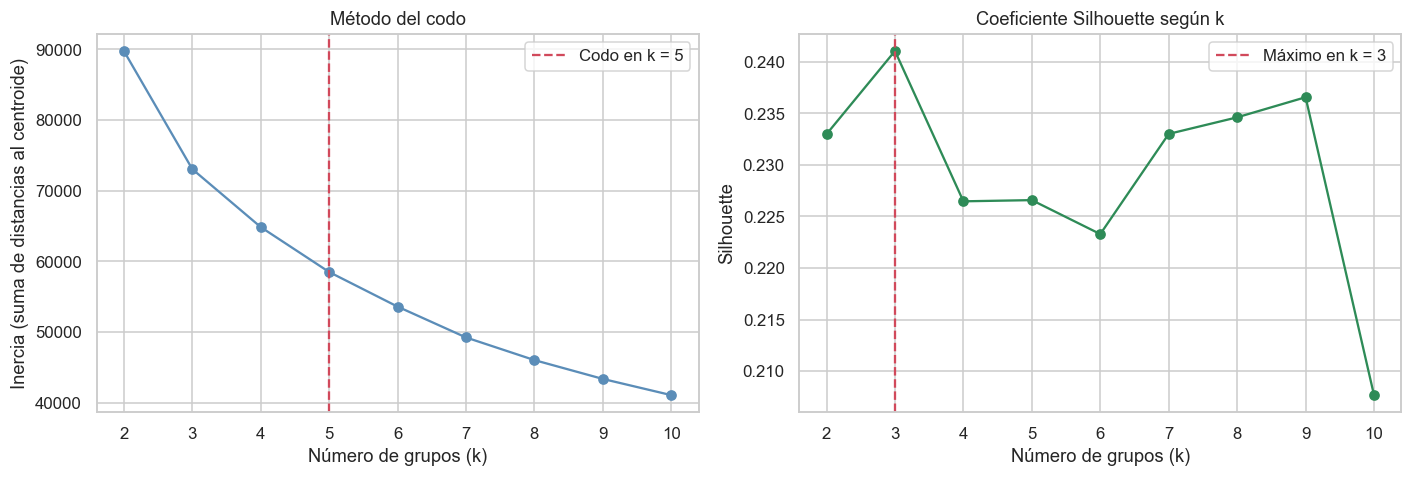

In [19]:
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.5))

eje1.plot(tabla_k.index, tabla_k["Inercia"], "o-", color="#5B8DB8")
eje1.axvline(k_codo, ls="--", color="#D1495B", label=f"Codo en k = {k_codo}")
eje1.set_title("Método del codo")
eje1.set_xlabel("Número de grupos (k)")
eje1.set_ylabel("Inercia (suma de distancias al centroide)")
eje1.legend()

eje2.plot(tabla_k.index, tabla_k["Silhouette"], "o-", color="#2E8B57")
eje2.axvline(k_silhouette, ls="--", color="#D1495B", label=f"Máximo en k = {k_silhouette}")
eje2.set_title("Coeficiente Silhouette según k")
eje2.set_xlabel("Número de grupos (k)")
eje2.set_ylabel("Silhouette")
eje2.legend()

plt.tight_layout()
guardar_figura("modelo_01_kmeans_codo_silhouette")
plt.show()

### Elección final de k

El codo sale en k = 5 y ese es el que uso. Silhouette tiene su máximo en k = 3, pero la diferencia es tan pequeña que preferí cinco grupos, porque dicen mucho más sobre los clientes. Si se quiere probar otro valor basta con cambiar `K_ELEGIDO` y volver a correr desde aquí.

In [20]:
K_ELEGIDO = k_codo

inicio = time.perf_counter()
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA)
etiquetas_km = kmeans.fit_predict(X)
tiempo_km = time.perf_counter() - inicio

print(f"K-Means con k = {K_ELEGIDO} entrenado en {tiempo_km:.3f} s")
print("Clientes por grupo:")
print(pd.Series(etiquetas_km).value_counts().sort_index().to_string())

K-Means con k = 5 entrenado en 0.150 s
Clientes por grupo:
0    1156
1    1498
2    2317
3    2174
4    1804


### 5.2 DBSCAN, elección de eps y min_samples

- `min_samples`: parto de la regla práctica de usar el doble del número de variables.
- `eps`: uso la gráfica de distancia al vecino número `min_samples`. Ordeno esas distancias de menor a mayor y busco el codo de la curva, que es donde los puntos empiezan a quedar en zonas poco densas.

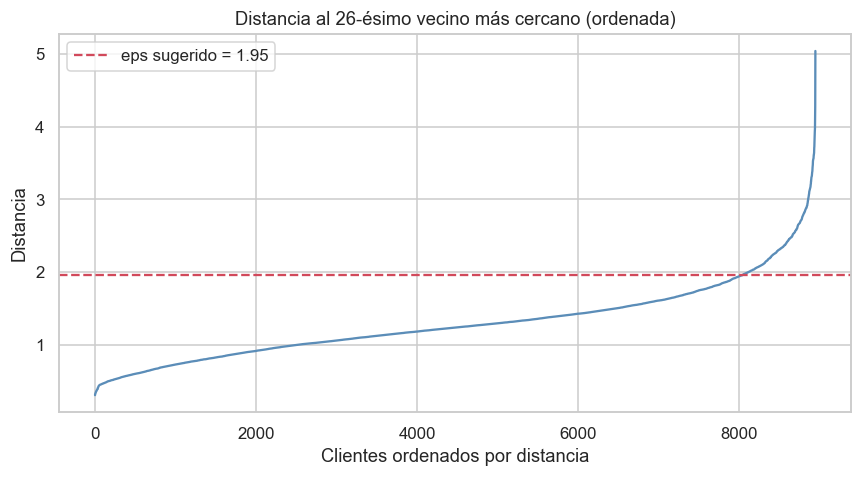

min_samples base: 26
eps sugerido por el codo: 1.953


In [21]:
MIN_SAMPLES_BASE = 2 * X.shape[1]

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES_BASE).fit(X)
distancias, _ = vecinos.kneighbors(X)
distancia_k = np.sort(distancias[:, -1])

indice_codo = punto_de_codo(np.arange(len(distancia_k)), distancia_k)
eps_codo = float(distancia_k[indice_codo])

plt.figure(figsize=(8, 4.5))
plt.plot(distancia_k, color="#5B8DB8")
plt.axhline(eps_codo, ls="--", color="#D1495B", label=f"eps sugerido = {eps_codo:.2f}")
plt.title(f"Distancia al {MIN_SAMPLES_BASE}-ésimo vecino más cercano (ordenada)")
plt.xlabel("Clientes ordenados por distancia")
plt.ylabel("Distancia")
plt.legend()
plt.tight_layout()
guardar_figura("modelo_02_dbscan_k_distancia")
plt.show()

print(f"min_samples base: {MIN_SAMPLES_BASE}")
print(f"eps sugerido por el codo: {eps_codo:.3f}")

### Búsqueda de parámetros de DBSCAN

Tomando el eps sugerido como referencia, pruebo nueve valores alrededor de él con tres valores de `min_samples`. Me quedo con la combinación de mayor Silhouette entre las que forman al menos dos grupos y dejan como mucho un 15 % de ruido.

In [22]:
MAX_RUIDO = 15

valores_eps = np.round(eps_codo * np.arange(0.6, 1.45, 0.1), 3)
valores_min_samples = sorted({max(3, MIN_SAMPLES_BASE // 2), MIN_SAMPLES_BASE, int(MIN_SAMPLES_BASE * 1.5)})

resultados_db = []
for eps in valores_eps:
    for ms in valores_min_samples:
        inicio = time.perf_counter()
        etiquetas = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        duracion = time.perf_counter() - inicio
        fila = {"eps": eps, "min_samples": ms, "Tiempo (s)": duracion}
        fila.update(metricas_clustering(X, etiquetas))
        resultados_db.append(fila)

tabla_db = pd.DataFrame(resultados_db)
guardar_tabla(tabla_db.set_index(["eps", "min_samples"]), "dbscan_busqueda_parametros")

validas = tabla_db[(tabla_db["n_clusters"] >= 2) & (tabla_db["% ruido"] <= MAX_RUIDO)]
if validas.empty:
    print(f"Ninguna combinación cumple (>= 2 grupos y <= {MAX_RUIDO}% de ruido).")
    validas = tabla_db[tabla_db["n_clusters"] >= 2]
    if not validas.empty:
        print("Se elige la de mayor Silhouette entre las que forman al menos 2 grupos.")

if validas.empty:
    print("DBSCAN no logra formar 2 o más grupos con estos parámetros; se usa el eps del codo.")
    mejor = {"eps": eps_codo, "min_samples": MIN_SAMPLES_BASE}
else:
    mejor = validas.sort_values("Silhouette", ascending=False).iloc[0]

EPS_ELEGIDO = float(mejor["eps"])
MIN_SAMPLES_ELEGIDO = int(mejor["min_samples"])
print(f"Parámetros elegidos: eps = {EPS_ELEGIDO:.3f}, min_samples = {MIN_SAMPLES_ELEGIDO}")
tabla_db.sort_values("Silhouette", ascending=False).head(10)

Parámetros elegidos: eps = 2.344, min_samples = 39


,eps,min_samples,Tiempo (s),n_clusters,% ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
4,1.367,26,2.403,2,15.421,0.430,0.593,186.228
20,2.344,39,4.982,2,1.564,0.414,0.802,584.641
16,2.148,26,2.181,2,1.732,0.414,0.807,585.767
19,2.344,26,4.365,2,1.184,0.409,0.847,622.499
23,2.539,39,3.747,2,1.050,0.407,0.855,626.946
7,1.563,26,2.892,3,8.738,0.403,0.691,180.644
14,1.953,39,2.267,3,3.665,0.398,0.690,207.649
10,1.758,26,2.400,3,4.861,0.397,0.730,231.669
6,1.563,13,2.212,3,5.632,0.396,0.902,302.964
13,1.953,26,2.603,3,2.715,0.390,0.874,283.139


In [23]:
inicio = time.perf_counter()
dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=MIN_SAMPLES_ELEGIDO)
etiquetas_db = dbscan.fit_predict(X)
tiempo_db = time.perf_counter() - inicio

print(f"DBSCAN entrenado en {tiempo_db:.3f} s")
print("Clientes por grupo (-1 = ruido):")
print(pd.Series(etiquetas_db).value_counts().sort_index().to_string())

DBSCAN entrenado en 4.318 s
Clientes por grupo (-1 = ruido):
-1     140
 0    8668
 1     141


## Fase 6. Evaluación del desempeño

Estas son las métricas con las que comparo los dos algoritmos.

| Métrica | Qué mide | Qué conviene |
|---|---|---|
| Silhouette | Qué tan cerca está cada punto de su propio grupo comparado con el grupo vecino, va de menos 1 a 1 | Que sea alto |
| Davies-Bouldin | Qué tan dispersos son los grupos por dentro frente a qué tan separados están entre sí | Que sea bajo |
| Calinski-Harabasz | La separación entre grupos frente a la dispersión dentro de ellos | Que sea alto |
| Porcentaje de ruido | Los clientes que DBSCAN no mete en ningún grupo | Depende del objetivo |
| Tamaño de los grupos | Si los grupos están equilibrados o hay algunos muy pequeños | Grupos que sirvan para algo |
| Tiempo de ejecución | Lo que tarda cada algoritmo | Que sea bajo |

En DBSCAN calculo las métricas sin los puntos de ruido, que es lo que se hace normalmente.

In [24]:
def resumen_modelo(nombre, parametros, etiquetas, tiempo):
    fila = {"Algoritmo": nombre, "Parámetros": parametros}
    fila.update(metricas_clustering(X, etiquetas))
    tamanos = pd.Series(etiquetas[etiquetas != -1]).value_counts()
    fila["Grupo más grande (%)"] = tamanos.max() / len(etiquetas) * 100 if len(tamanos) else np.nan
    fila["Grupo más pequeño (%)"] = tamanos.min() / len(etiquetas) * 100 if len(tamanos) else np.nan
    fila["Tiempo (s)"] = tiempo
    return fila


comparacion = pd.DataFrame([
    resumen_modelo("K-Means", f"k = {K_ELEGIDO}", etiquetas_km, tiempo_km),
    resumen_modelo("DBSCAN", f"eps = {EPS_ELEGIDO:.3f}, min_samples = {MIN_SAMPLES_ELEGIDO}",
                   etiquetas_db, tiempo_db),
]).set_index("Algoritmo")
guardar_tabla(comparacion, "comparacion_algoritmos")
comparacion

,Parámetros,n_clusters,% ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo más grande (%),Grupo más pequeño (%),Tiempo (s)
Algoritmo,,,,,,,,,
K-Means,k = 5,5,0.000,0.227,1.541,"2,211.518",25.891,12.918,0.150
DBSCAN,"eps = 2.344, min_samples = 39",2,1.564,0.414,0.802,584.641,96.860,1.576,4.318


### Comparación de las métricas

Pongo las tres métricas internas en barras, una al lado de la otra.

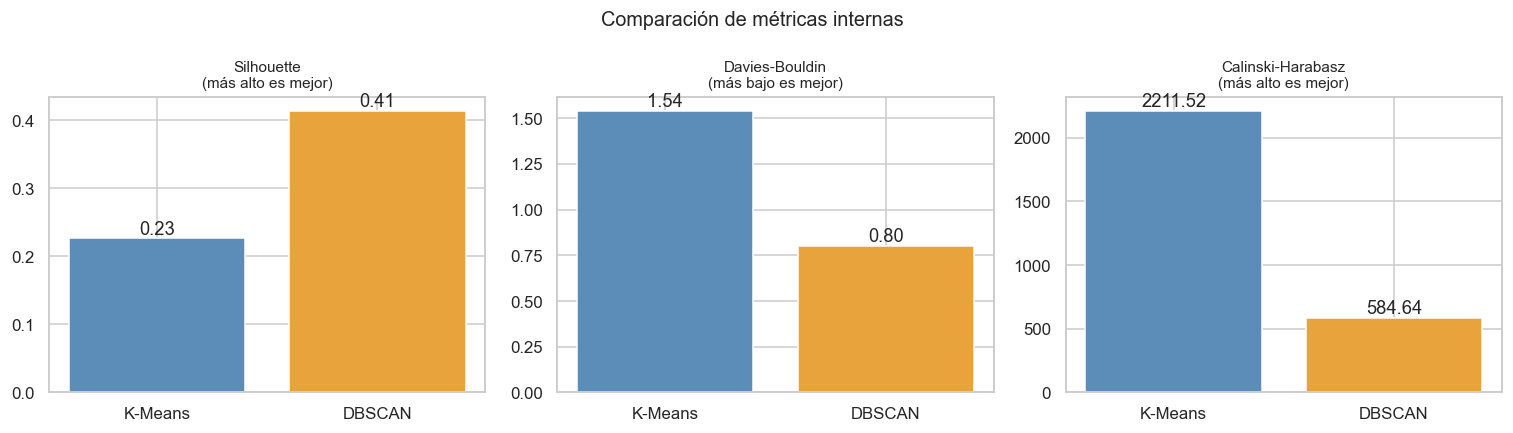

In [25]:
METRICAS = [("Silhouette", "más alto es mejor"),
            ("Davies-Bouldin", "más bajo es mejor"),
            ("Calinski-Harabasz", "más alto es mejor")]
COLORES = ["#5B8DB8", "#E8A33D"]

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, (metrica, nota) in zip(ejes, METRICAS):
    valores = comparacion[metrica]
    barras = eje.bar(valores.index, valores.values, color=COLORES)
    eje.bar_label(barras, fmt="%.2f")
    eje.set_title(f"{metrica}\n({nota})", fontsize=10)
fig.suptitle("Comparación de métricas internas", fontsize=13)
plt.tight_layout()
guardar_figura("eval_01_comparacion_metricas")
plt.show()

### Los grupos vistos en dos dimensiones

Uso las dos componentes del PCA para dibujar los grupos de cada algoritmo. En DBSCAN el ruido sale en gris.

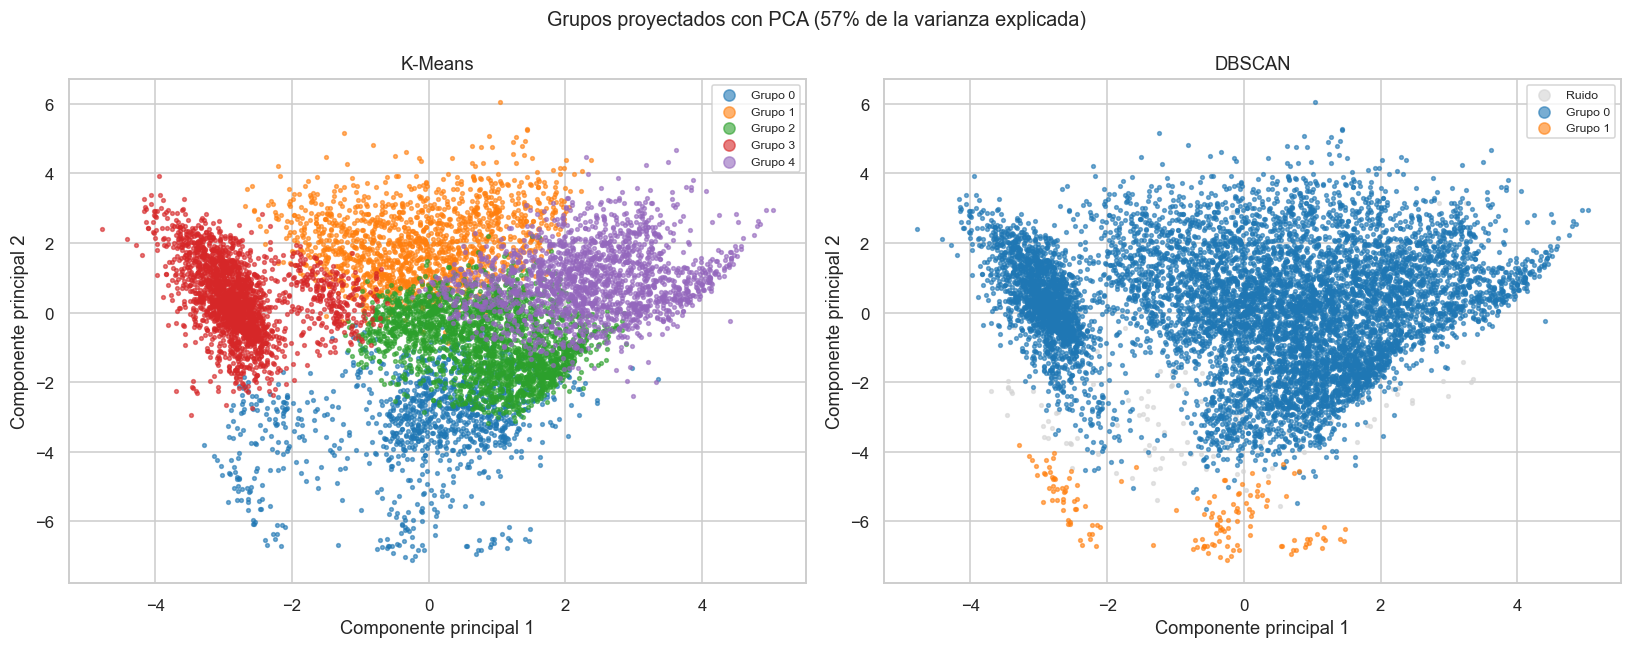

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))

for eje, (nombre, etiquetas) in zip(ejes, [("K-Means", etiquetas_km), ("DBSCAN", etiquetas_db)]):
    paleta = sns.color_palette("tab10")
    for g in sorted(set(etiquetas)):
        m = etiquetas == g
        if g == -1:
            eje.scatter(X_2d[m, 0], X_2d[m, 1], s=6, c="lightgray", label="Ruido", alpha=0.6)
        else:
            eje.scatter(X_2d[m, 0], X_2d[m, 1], s=6, color=paleta[g % len(paleta)],
                        label=f"Grupo {g}", alpha=0.6)
    eje.set_title(nombre)
    eje.set_xlabel("Componente principal 1")
    eje.set_ylabel("Componente principal 2")
    eje.legend(markerscale=3, fontsize=8, loc="best")

fig.suptitle(f"Grupos proyectados con PCA ({varianza_2d:.0%} de la varianza explicada)", fontsize=13)
plt.tight_layout()
guardar_figura("eval_02_grupos_pca")
plt.show()

### Tamaño de cada grupo

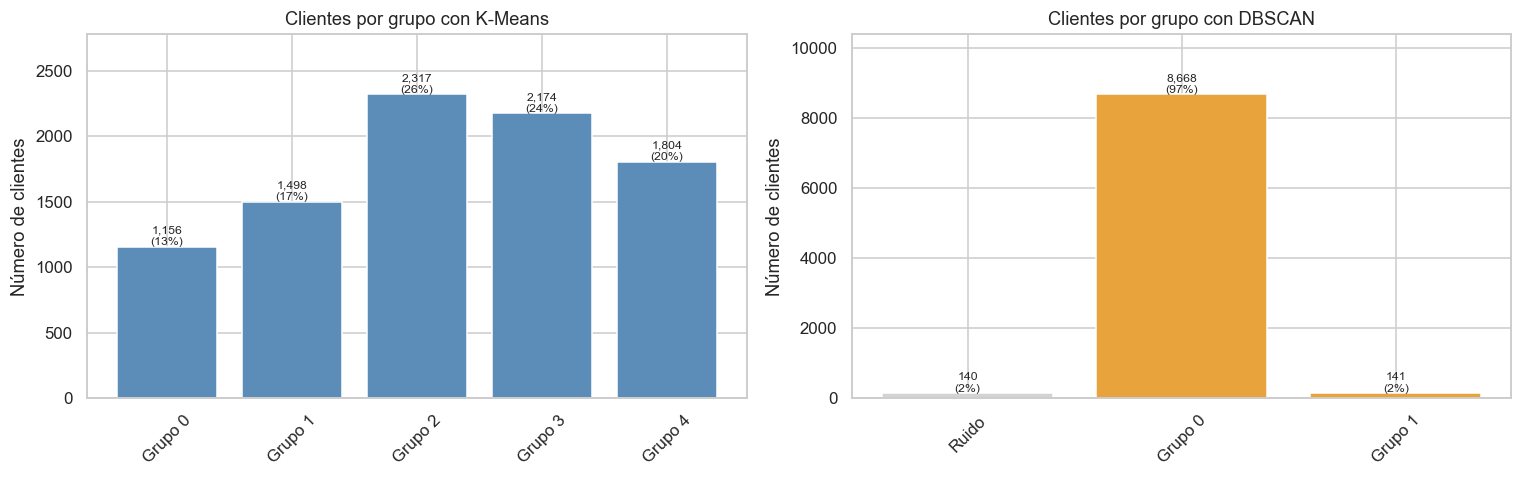

In [27]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

for eje, (nombre, etiquetas, color) in zip(
    ejes, [("K-Means", etiquetas_km, COLORES[0]), ("DBSCAN", etiquetas_db, COLORES[1])]
):
    conteo = pd.Series(etiquetas).value_counts().sort_index()
    nombres = ["Ruido" if g == -1 else f"Grupo {g}" for g in conteo.index]
    colores = ["lightgray" if g == -1 else color for g in conteo.index]
    barras = eje.bar(nombres, conteo.values, color=colores)
    eje.bar_label(barras, labels=[f"{v:,}\n({v / len(etiquetas):.0%})" for v in conteo.values], fontsize=8)
    eje.set_title(f"Clientes por grupo con {nombre}")
    eje.set_ylabel("Número de clientes")
    eje.tick_params(axis="x", rotation=45)
    eje.margins(y=0.2)

plt.tight_layout()
guardar_figura("eval_03_tamano_grupos")
plt.show()

## Fase 7. Interpretación de los resultados

Para ponerle nombre a cada grupo calculo el promedio de cada variable por grupo, en la escala original. También hago un mapa de calor con los valores estandarizados, que muestra cuánto se aleja cada grupo del promedio general en desviaciones estándar. Debajo del mapa imprimo, para cada grupo, las variables en las que más se sale del promedio, hacia arriba y hacia abajo.

In [28]:
VARIABLES_PERFIL = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
    "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS",
    "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT", "TENURE",
]
VARIABLES_PERFIL = [c for c in VARIABLES_PERFIL if c in datos.columns]


def perfil_grupos(etiquetas, nombre):
    tabla = datos[VARIABLES_PERFIL].copy()
    tabla["Grupo"] = etiquetas
    tabla = tabla[tabla["Grupo"] != -1]
    perfil = tabla.groupby("Grupo").mean()
    perfil.insert(0, "Clientes", tabla["Grupo"].value_counts().sort_index())
    guardar_tabla(perfil, f"perfil_{nombre.lower().replace('-', '')}")
    return perfil


def mapa_perfiles(etiquetas, nombre, archivo):
    z = datos_log[VARIABLES_PERFIL].apply(lambda s: (s - s.mean()) / s.std())
    z["Grupo"] = etiquetas
    z = z[z["Grupo"] != -1].groupby("Grupo").mean()
    plt.figure(figsize=(13, 0.6 * len(z) + 2.5))
    sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, linewidths=0.5,
                cbar_kws={"label": "Desviaciones estándar respecto al promedio"})
    plt.title(f"Perfil de los grupos de {nombre}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    guardar_figura(archivo)
    plt.show()
    return z


def describir_grupos(z, n=3):
    for grupo, fila in z.iterrows():
        altas = fila.sort_values(ascending=False).head(n)
        bajas = fila.sort_values().head(n)
        print(f"Grupo {grupo}:")
        print("   Alto en: " + ", ".join(f"{v} ({fila[v]:+.1f})" for v in altas.index if fila[v] > 0.3))
        print("   Bajo en: " + ", ".join(f"{v} ({fila[v]:+.1f})" for v in bajas.index if fila[v] < -0.3))

### 7.1 Perfiles de K-Means

In [29]:
perfil_km = perfil_grupos(etiquetas_km, "K-Means")
perfil_km

,Clientes,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Grupo,,,,,,,,,,,,,
0,1156,110.416,303.688,188.525,115.768,186.661,0.289,0.029,"3,526.113",667.128,93.127,0.184,11.267
1,1498,"3,374.252","1,251.608",743.618,508.227,"2,669.748",0.603,0.341,"5,990.988","2,840.966","1,620.336",0.032,11.511
2,2317,590.078,627.889,102.761,525.650,53.182,0.696,0.014,"2,911.774",806.884,691.992,0.239,11.523
3,2174,"2,228.025",11.309,9.846,1.503,"1,976.669",0.015,0.279,"3,989.614","1,653.585","1,049.623",0.032,11.407
4,1804,"1,446.133","2,923.120","2,057.061",866.244,69.371,0.835,0.015,"6,513.381","2,782.827",591.354,0.273,11.811


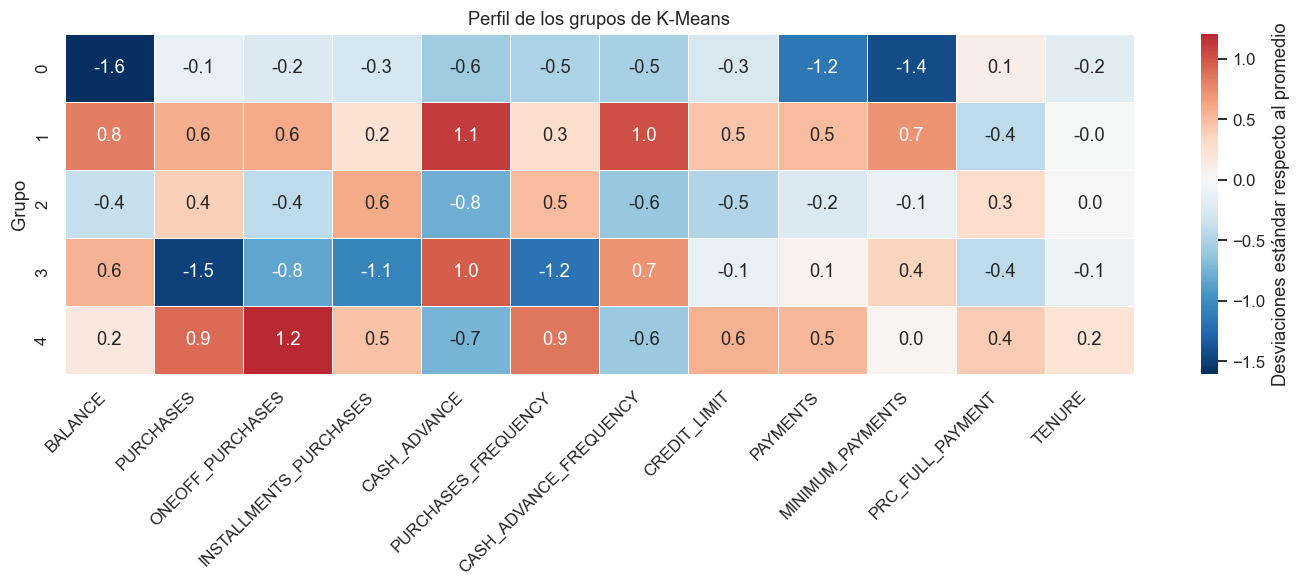

Grupo 0:
   Alto en: 
   Bajo en: BALANCE (-1.6), MINIMUM_PAYMENTS (-1.4), PAYMENTS (-1.2)
Grupo 1:
   Alto en: CASH_ADVANCE (+1.1), CASH_ADVANCE_FREQUENCY (+1.0), BALANCE (+0.8)
   Bajo en: PRC_FULL_PAYMENT (-0.4)
Grupo 2:
   Alto en: INSTALLMENTS_PURCHASES (+0.6), PURCHASES_FREQUENCY (+0.5), PURCHASES (+0.4)
   Bajo en: CASH_ADVANCE (-0.8), CASH_ADVANCE_FREQUENCY (-0.6), CREDIT_LIMIT (-0.5)
Grupo 3:
   Alto en: CASH_ADVANCE (+1.0), CASH_ADVANCE_FREQUENCY (+0.7), BALANCE (+0.6)
   Bajo en: PURCHASES (-1.5), PURCHASES_FREQUENCY (-1.2), INSTALLMENTS_PURCHASES (-1.1)
Grupo 4:
   Alto en: ONEOFF_PURCHASES (+1.2), PURCHASES (+0.9), PURCHASES_FREQUENCY (+0.9)
   Bajo en: CASH_ADVANCE (-0.7), CASH_ADVANCE_FREQUENCY (-0.6)


In [30]:
z_km = mapa_perfiles(etiquetas_km, "K-Means", "interp_01_perfiles_kmeans")
describir_grupos(z_km)

### 7.2 Perfiles de DBSCAN

,Clientes,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Grupo,,,,,,,,,,,,,
0,8668,"1,593.811","1,014.647",594.722,420.233,983.687,0.497,0.136,"4,506.360","1,753.913",861.078,0.156,11.537
1,141,59.686,149.902,75.462,74.440,530.163,0.199,0.054,"3,611.702",0.000,0.000,0.000,10.610


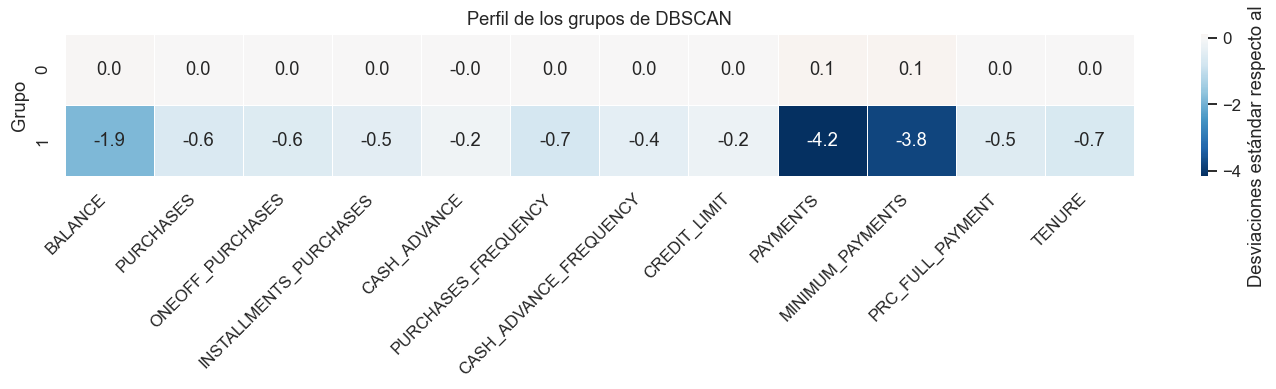

Grupo 0:
   Alto en: 
   Bajo en: 
Grupo 1:
   Alto en: 
   Bajo en: PAYMENTS (-4.2), MINIMUM_PAYMENTS (-3.8), BALANCE (-1.9)


In [31]:
if len(set(etiquetas_db) - {-1}) >= 1:
    perfil_db = perfil_grupos(etiquetas_db, "DBSCAN")
    display(perfil_db)
    z_db = mapa_perfiles(etiquetas_db, "DBSCAN", "interp_02_perfiles_dbscan")
    describir_grupos(z_db)
else:
    print("DBSCAN no formó grupos (todo es ruido).")

### 7.3 Los clientes que DBSCAN marca como ruido

Quise ver quiénes son estos clientes comparando sus promedios con los del resto. Así se puede saber si son casos raros con sentido para el negocio, por ejemplo gastos o avances muy altos.

In [32]:
es_ruido = etiquetas_db == -1
if es_ruido.any():
    comparacion_ruido = pd.DataFrame({
        "Ruido (promedio)": datos.loc[es_ruido, VARIABLES_PERFIL].mean(),
        "Resto (promedio)": datos.loc[~es_ruido, VARIABLES_PERFIL].mean(),
    })
    comparacion_ruido["Ruido / Resto"] = comparacion_ruido["Ruido (promedio)"] / comparacion_ruido["Resto (promedio)"]
    guardar_tabla(comparacion_ruido, "dbscan_ruido_vs_resto")
    print(f"Clientes marcados como ruido: {es_ruido.sum():,} ({es_ruido.mean():.1%})")
    display(comparacion_ruido)
else:
    print("DBSCAN no marcó ningún cliente como ruido.")

Clientes marcados como ruido: 140 (1.6%)


,Ruido (promedio),Resto (promedio),Ruido / Resto
BALANCE,"1,274.711","1,569.256",0.812
PURCHASES,"1,161.305","1,000.806",1.160
ONEOFF_PURCHASES,975.880,586.411,1.664
INSTALLMENTS_PURCHASES,185.582,414.698,0.448
CASH_ADVANCE,"1,138.254",976.428,1.166
PURCHASES_FREQUENCY,0.372,0.492,0.756
CASH_ADVANCE_FREQUENCY,0.149,0.135,1.104
CREDIT_LIMIT,"4,646.071","4,492.040",1.034
PAYMENTS,"2,205.079","1,725.839",1.278
MINIMUM_PAYMENTS,165.129,847.296,0.195


### 7.4 Guardar los resultados

Guardo el dataset con el grupo que cada algoritmo le asignó a cada cliente, en `data/processed/cc_con_grupos.csv`.

In [33]:
resultado_final = datos.copy()
resultado_final["grupo_kmeans"] = etiquetas_km
resultado_final["grupo_dbscan"] = etiquetas_db
resultado_final.to_csv(DIR_PROCESADOS / "cc_con_grupos.csv", index=False)

print("Archivos generados:")
for carpeta in [DIR_PROCESADOS, DIR_FIGURAS, DIR_TABLAS]:
    for archivo in sorted(carpeta.glob("*.*")):
        print("  ", archivo.relative_to(RAIZ))

Archivos generados:


   data\processed\.gitkeep
   data\processed\cc_con_grupos.csv
   data\processed\cc_limpio.csv
   data\processed\cc_preparado_estandarizado.csv
   reports\figures\.gitkeep
   reports\figures\diagrama_bloques.pdf
   reports\figures\diagrama_bloques.png
   reports\figures\eda_01_diagramas_caja.png
   reports\figures\eda_02_histogramas.png
   reports\figures\eda_03_matriz_correlacion.png
   reports\figures\eda_04_dispersion.png
   reports\figures\eval_01_comparacion_metricas.png
   reports\figures\eval_02_grupos_pca.png
   reports\figures\eval_03_tamano_grupos.png
   reports\figures\interp_01_perfiles_kmeans.png
   reports\figures\interp_02_perfiles_dbscan.png
   reports\figures\modelo_01_kmeans_codo_silhouette.png
   reports\figures\modelo_02_dbscan_k_distancia.png
   reports\tablas\.gitkeep
   reports\tablas\asimetria_antes_despues_log.csv
   reports\tablas\comparacion_algoritmos.csv
   reports\tablas\correlaciones_altas.csv
   reports\tablas\dbscan_busqueda_parametros.csv
   reports\t

### Interpretación y selección del algoritmo

#### Elección de k en K-Means

El codo sale en k = 5. Silhouette casi no cambia entre k = 2 y k = 9, siempre entre 0,22 y 0,24, y su máximo está en k = 3 (0,241). Como la diferencia es mínima me quedé con k = 5, porque con tres grupos se pierde mucho detalle.

#### Perfiles que encontré con K-Means

| Grupo | Clientes | Nombre que le puse | Rasgos principales (promedios) |
|---|---|---|---|
| 4 | 1.804 (20 %) | Compradores frecuentes de alto gasto | Compran 2.923, con frecuencia de compra de 0,84, tienen el cupo más alto (6.513) y casi no sacan avances. Pagan el total el 27 % de los meses |
| 2 | 2.317 (26 %) | Compradores a cuotas | Compras moderadas (628), casi todas a cuotas (526), frecuencia de 0,70, cupo bajo y casi sin avances |
| 1 | 1.498 (17 %) | Revolventes de alto saldo | El saldo más alto (3.374), usan tanto compras como avances (2.670) y tienen pagos mínimos altos. Pagan el total solo el 3 % de los meses, así que es un perfil de riesgo |
| 3 | 2.174 (24 %) | Usuarios de avances en efectivo | Casi no compran (11), usan la tarjeta para sacar efectivo (1.977) y tienen saldo alto (2.228), otro perfil de riesgo |
| 0 | 1.156 (13 %) | Inactivos o de bajo uso | Saldo casi nulo (110), compras bajas (304) y frecuencia de compra de 0,29 |

#### Lo que hizo DBSCAN

Usé eps = 2,34 y min_samples = 39.

- Grupo principal: tiene el 96,9 % de los clientes.
- Grupo pequeño: 141 clientes (1,6 %). De ellos, 140 no hicieron ni un pago en seis meses, y todos quedaron también en el grupo de inactivos de K-Means. Ese grupo sí tiene valor, porque son posibles casos de impago.
- Ruido: el 1,6 % de los clientes. Comparados con el resto, hacen 1,7 veces más compras en un solo pago y pagan mucho menos en mínimos, más o menos la quinta parte.
- Por qué no segmenta: la gráfica de distancia al vecino crece de forma continua, sin un salto claro. Eso quiere decir que los clientes forman una sola masa de densidad parecida y no grupos separados por zonas vacías, y por eso DBSCAN no logra partirla en segmentos.

#### Comparación de métricas

| Métrica | K-Means | DBSCAN | Cómo lo leo |
|---|---|---|---|
| Silhouette | 0,227 | 0,414 | DBSCAN sale más alto, pero porque compara un grupo gigante con uno pequeño y muy distinto, no porque segmente mejor |
| Davies-Bouldin | 1,54 | 0,80 | Mejor en DBSCAN, por la misma razón |
| Calinski-Harabasz | 2.212 | 585 | Mucho mejor en K-Means, sus grupos son más compactos y están más separados |
| Porcentaje de ruido | 0 % | 1,6 % | DBSCAN detecta atípicos y K-Means mete a todos en algún grupo |
| Tamaños | Entre 13 % y 26 % | 96,9 % y 1,6 % | Los grupos de K-Means son parejos y se pueden usar |
| Tiempo | Cerca de 0,15 s | Cerca de 4 s | K-Means es más rápido |

Hay que decir que el Silhouette de K-Means, cerca de 0,23, indica una estructura entre débil y moderada. Los clientes no vienen separados en grupos naturales, forman más bien un continuo que K-Means reparte en zonas con comportamientos distintos. Lo dejo anotado como limitación.

#### Algoritmo elegido

Para responder la pregunta de investigación me quedo con K-Means.

- Perfiles: encuentra cinco perfiles claros, de tamaño parejo y que tienen sentido para el negocio.
- Métricas: tiene el mejor Calinski-Harabasz y es el más rápido.
- Frente a DBSCAN: DBSCAN saca mejor Silhouette y Davies-Bouldin, pero solo porque deja a casi todos en un mismo grupo, y eso no sirve para segmentar.

Aun así DBSCAN me sirve como complemento, porque encuentra a los 141 clientes que no pagan y al 1,6 % de atípicos, dos listas útiles para un área de riesgo.

#### Recomendaciones para la entidad

- Compradores frecuentes de alto gasto: programas de fidelización, beneficios y aumentos de cupo.
- Compradores a cuotas: promociones de cuotas sin interés y alianzas con comercios.
- Revolventes de alto saldo: seguimiento de riesgo y ofertas para refinanciar o unificar la deuda.
- Usuarios de avances en efectivo: monitoreo de riesgo y ofrecerles otros productos, como un crédito de libre inversión.
- Inactivos: campañas para reactivarlos, empezando por los clientes sin pagos que encontró DBSCAN.

## Referencias

- Bhasin, A. (2018). Credit card dataset for clustering [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/arjunbhasin2013/ccdata
- Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. Communications in Statistics, 3(1), 1-27.
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1(2), 224-227.
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96) (pp. 226-231). AAAI Press.
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. En Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability (Vol. 1, pp. 281-297). University of California Press.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.